# Stage 3 — Sensors and the guard under stress

**Vamsi Gudipati**

The ladle twin reconstructs a 96×64 temperature field from 16 thermocouples and the gas flow, on an 8-mode POD basis, and flags fields its basis cannot represent by their leftover energy. Stage 1 showed that a reduced model is only as good as the family it was built on. Here I ask two questions Stage 2 leaves open, with its own data, basis, split and noise model (rebuilt from `ladle_v2.py` exactly as in Stage 2), and with the seeds 0, 1 and 2.

- **A. How many sensors the twin needs.** Field reconstruction error against the number of sensors m, from 2 up to the 8 modes and beyond (2 to 32), with sensors at the QR/DEIM pivots of the modes (`place_sensors` in `ladle_v2.py`) against random positions (a different random layout per seed). Two reconstructions: gappy POD (least squares of the readings onto the modes at the sensor cells, `gappy_reconstruct`) and the twin's learned linear map (ridge regression from the readings and the gas flow to the 8 coefficients, trained on the training heats). Thermocouple noise as in Stage 2 (2 K), drawn per seed.
- **B. The guard under stress.** (1) Drift: each test heat is moved towards the abnormal double-plume regime by adding a fraction α of the double-plume structure that `ladle_v2.temperature` adds for the same operating point (α = 0 is the normal heat, α = 1 the full abnormal field); detection rate against α. (2) Noise: Gaussian noise on the 16 thermocouples with a standard deviation of 0, 1, 5 and 10 % of each sensor's signal standard deviation over the training heats; the soft sensor's field error and the guard's false alarms. Two guards: the twin's own, on the true field (leftover energy after projection onto the 8 modes), and the same idea in sensor space, which is what a plant can compute: the share of the 16 readings that the 8 modes cannot fit by least squares. Thresholds are the 99th percentile of the score on a calibration block of normal heats that neither training nor testing uses (plant-time heats 300–374, between Stage 2's training and test blocks).

Portfolio page: https://vamsigudipati.github.io/rom-ladle-digital-twin.html

In [1]:
# Where this notebook writes its outputs (paths relative to notebooks/)
from pathlib import Path
STAGE = "03_sensors_and_guard"
RESULTS_DIR = Path("../results") / STAGE
EXERCISES_DIR = RESULTS_DIR / "exercises"
MODELS_DIR = Path("../models") / STAGE
ANIM_DIR = Path("../animations")
ANIM_PREFIX = "03_"
for _d in (RESULTS_DIR, EXERCISES_DIR, MODELS_DIR, ANIM_DIR):
    _d.mkdir(parents=True, exist_ok=True)

In [2]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
sys.path.insert(0, ".")                       # ladle_v2.py sits next to this notebook
from ladle_v2 import generate, volume_weights, temperature, place_sensors, gappy_reconstruct
RES = RESULTS_DIR
SEEDS = (0, 1, 2)
CB = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
# Stage 2's data, basis, split and helpers
g, F, reg, lat = generate(); nz, nr, R, H = g["nz"], g["nr"], g["R"], g["H"]; r, z = g["r"], g["z"]
wg = volume_weights(g); sw = np.sqrt(wg)
s = np.where(reg == "single")[0]; tr, cal, te = s[:300], s[300:375], s[375:]; ood = np.where(reg == "double")[0]
Xtr = F[tr].reshape(len(tr), -1); Tmean = Xtr.mean(0)
U, S, Vt = np.linalg.svd((Xtr - Tmean) * sw[None, :], full_matrices=False); basis = (Vt / sw[None, :])[:8]; K = 8
def coeffs(fields): return ((fields.reshape(len(fields), -1) - Tmean) * wg[None, :]) @ basis.T
def relL2(Fhat, Ftrue):
    num = (((Fhat - Ftrue).reshape(len(Ftrue), -1)**2) * wg).sum(1); den = (((Ftrue.reshape(len(Ftrue), -1) - Tmean)**2) * wg).sum(1) + 1e-12
    return np.sqrt(num / den)
def rmsK(Fhat, Ftrue): return np.sqrt((((Fhat - Ftrue).reshape(len(Ftrue), -1)**2) * wg).sum(1) / wg.sum())
def cell(rr, zz): return int(np.argmin(np.abs(z - zz))) * nr + int(np.argmin(np.abs(r - rr)))
probes16 = [cell(rr * R, zz * H) for rr in (0.1, 0.9) for zz in np.linspace(0.06, 0.94, 8)]
Q = lat[:, 0] / 5e-4
print("fields", F.shape, "| train / calibration / test / abnormal:", len(tr), len(cal), len(te), len(ood))

fields (620, 96, 64) | train / calibration / test / abnormal: 300 75 125 120


## A. How many sensors
For each m the QR/DEIM layout is `place_sensors(basis, g, m)` (pivoted QR on the 8 modes, 2-cell border excluded, as in `ladle_v2.py`); the random layout draws m cells without replacement from the same candidate cells with `default_rng(100 + seed)`. Every reading carries Gaussian noise of 2 K (Stage 2's), drawn with `default_rng(seed)` for the training heats then the test heats. Gappy POD needs no training; the ridge map (α = 1, Stage 2's) is trained on the 300 training heats with the gas flow as an extra input, as Stage 2's soft sensor is. Errors are Stage 2's variation-relative L2 error and the root-mean-square error in kelvin, mean over the 125 test heats. The condition number of the modes sampled at the sensors says how well posed the gappy inverse is. Because a random layout can make that inverse nearly singular, the summary gives the median over the three seeds with the smallest and largest value, not a mean.

In [3]:
M_LIST = (2, 3, 4, 6, 8, 10, 12, 16, 24, 32)
nzr = np.arange(nz * nr); rr_, zz_ = nzr % nr, nzr // nr
cand = nzr[(rr_ >= 2) & (rr_ <= nr - 3) & (zz_ >= 2) & (zz_ <= nz - 3)]
rows_a = []
for seed in SEEDS:
    for m in M_LIST:
        for layout in ("QR/DEIM pivots", "random"):
            sel = place_sensors(basis, g, m=m) if layout == "QR/DEIM pivots" else np.random.default_rng(100 + seed).choice(cand, m, replace=False)
            rn = np.random.default_rng(seed)
            s_tr = F[tr].reshape(len(tr), -1)[:, sel] + rn.normal(0, 2.0, (len(tr), m)); s_te = F[te].reshape(len(te), -1)[:, sel] + rn.normal(0, 2.0, (len(te), m))
            gp = gappy_reconstruct(basis, Tmean, sel, s_te).reshape(-1, nz, nr)
            rd = Ridge(1.0).fit(np.column_stack([s_tr, Q[tr]]), coeffs(F[tr]))
            rf = (Tmean + rd.predict(np.column_stack([s_te, Q[te]])) @ basis).reshape(-1, nz, nr)
            rows_a.append(dict(seed=seed, m=m, layout=layout, cond=float(np.linalg.cond(basis[:, sel].T)),
                               gappy_relL2=relL2(gp, F[te]).mean(), gappy_rmsK=rmsK(gp, F[te]).mean(),
                               ridge_relL2=relL2(rf, F[te]).mean(), ridge_rmsK=rmsK(rf, F[te]).mean()))
A_runs = pd.DataFrame(rows_a); A_runs.to_csv(RES / "a_sensors_runs.csv", index=False)
A = A_runs.groupby(["layout", "m"])[["cond", "gappy_relL2", "gappy_rmsK", "ridge_relL2", "ridge_rmsK"]].agg(["median", "min", "max"])
A.columns = [f"{a}_{b}" for a, b in A.columns]; A.to_csv(RES / "a_sensors_summary.csv")
pd.set_option("display.width", 220); print(A.round(4).to_string())
ref16 = (Tmean + Ridge(1.0).fit(np.column_stack([F[tr].reshape(len(tr), -1)[:, probes16] + np.random.default_rng(0).normal(0, 2.0, (len(tr), 16)), Q[tr]]), coeffs(F[tr])).predict(
         np.column_stack([F[te].reshape(len(te), -1)[:, probes16] + np.random.default_rng(1).normal(0, 2.0, (len(te), 16)), Q[te]])) @ basis).reshape(-1, nz, nr)
print(f"for reference, Stage 2's two lances of 16 probes with the ridge map: {relL2(ref16, F[te]).mean():.4f}")

                    cond_median      cond_min      cond_max  gappy_relL2_median  gappy_relL2_min  gappy_relL2_max  gappy_rmsK_median  gappy_rmsK_min  gappy_rmsK_max  ridge_relL2_median  ridge_relL2_min  ridge_relL2_max  ridge_rmsK_median  ridge_rmsK_min  ridge_rmsK_max
layout         m                                                                                                                                                                                                                                                             
QR/DEIM pivots 2   1.070300e+00  1.070300e+00  1.070300e+00        9.985000e-01     9.985000e-01     9.985000e-01       2.372210e+01    2.372200e+01    2.372270e+01              1.0411           1.0409           1.0426            24.8012         24.7988         24.8393
               3   2.815400e+00  2.815400e+00  2.815400e+00        9.866000e-01     9.862000e-01     9.866000e-01       2.346220e+01    2.345410e+01    2.346400e+01              1.0378      

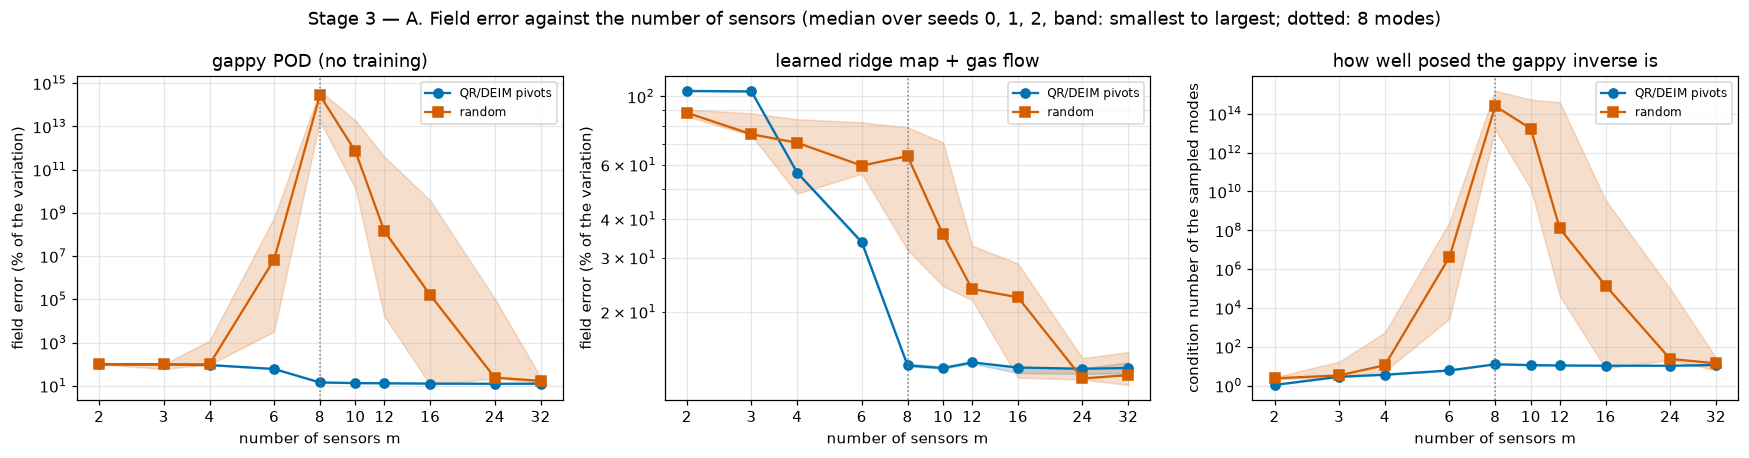

Result A (median over seeds, [min, max] for random): gappy relL2 at m = 8 / 16 / 32: QR 0.143 / 0.127 / 0.125, random 2.74e+12 [1.75e+11, 4.43e+12] / 1.59e+03 [0.11, 3.79e+07] / 0.168 [0.137, 0.251]; ridge at m = 8 / 16 / 32: QR 0.134 / 0.132 / 0.131, random 0.640 [0.317, 0.793] / 0.223 [0.122, 0.287] / 0.125 [0.116, 0.148]


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for layout, c, mk in (("QR/DEIM pivots", CB[0], "o"), ("random", CB[3], "s")):
    d = A.loc[layout]
    for a_, col, ls in ((ax[0], "gappy_relL2", "-"), (ax[1], "ridge_relL2", "-")):
        a_.plot(d.index, 100 * d[f"{col}_median"], mk + ls, color=c, label=layout); a_.fill_between(d.index, 100 * d[f"{col}_min"], 100 * d[f"{col}_max"], color=c, alpha=0.2)
    ax[2].plot(d.index, d["cond_median"], mk + "-", color=c, label=layout); ax[2].fill_between(d.index, d["cond_min"], d["cond_max"], color=c, alpha=0.2)
for a_, ttl in ((ax[0], "gappy POD (no training)"), (ax[1], "learned ridge map + gas flow")):
    a_.axvline(K, color="0.5", ls=":", lw=1); a_.set_xscale("log", base=2); a_.set_yscale("log"); a_.set_xticks(M_LIST, [str(m) for m in M_LIST])
    a_.set_xlabel("number of sensors m"); a_.set_ylabel("field error (% of the variation)"); a_.set_title(ttl); a_.legend(fontsize=8); a_.grid(alpha=0.3, which="both")
ax[2].axvline(K, color="0.5", ls=":", lw=1); ax[2].set_xscale("log", base=2); ax[2].set_yscale("log"); ax[2].set_xticks(M_LIST, [str(m) for m in M_LIST])
ax[2].set_xlabel("number of sensors m"); ax[2].set_ylabel("condition number of the sampled modes"); ax[2].set_title("how well posed the gappy inverse is"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3, which="both")
fig.suptitle("Stage 3 — A. Field error against the number of sensors (median over seeds 0, 1, 2, band: smallest to largest; dotted: 8 modes)"); plt.tight_layout(); plt.savefig(RES / "a_sensors.png", dpi=110); plt.show()
q, rd_ = A.loc["QR/DEIM pivots"], A.loc["random"]
print("Result A (median over seeds, [min, max] for random): gappy relL2 at m = 8 / 16 / 32: QR " + " / ".join(f"{q.loc[m, 'gappy_relL2_median']:.3f}" for m in (8, 16, 32)) + ", random " + " / ".join(f"{rd_.loc[m, 'gappy_relL2_median']:.3g} [{rd_.loc[m, 'gappy_relL2_min']:.3g}, {rd_.loc[m, 'gappy_relL2_max']:.3g}]" for m in (8, 16, 32))
      + "; ridge at m = 8 / 16 / 32: QR " + " / ".join(f"{q.loc[m, 'ridge_relL2_median']:.3f}" for m in (8, 16, 32)) + ", random " + " / ".join(f"{rd_.loc[m, 'ridge_relL2_median']:.3f} [{rd_.loc[m, 'ridge_relL2_min']:.3f}, {rd_.loc[m, 'ridge_relL2_max']:.3f}]" for m in (8, 16, 32)))

## B. The guard under stress
**Field-space guard** (Stage 2's): leftover energy of a field after projection onto the 8 modes, as in its Section 7. **Sensor-space guard**: for the 16 thermocouples of Stage 2, the least-squares fit of the readings minus the mean field onto the 8 modes sampled there, and the share of the readings' energy the fit leaves. Both thresholds are the 99th percentile of the score on the 75 calibration heats; the sensor-space threshold is calibrated once on noise-free readings, as on commissioning data, and, separately, recalibrated at each noise level.

**Drift.** For every test heat i, the abnormal structure is Δᵢ = `temperature(g, lat[i], "double") − temperature(g, lat[i], "single")`, and the drifted field is F[i] + α Δᵢ. Detection rate = share of the 125 test heats above the threshold, at α from 0 (false alarms) to 1. The sensor-space guard is run with 1 % noise and its threshold calibrated on the calibration heats with the same 1 % noise (calibrated without noise it flags every heat, as the noise part shows). Stage 2's own late abnormal heats (120, `reg == "double"`) are scored as well.

**Noise.** Noise standard deviation = fraction × the standard deviation of each thermocouple over the training heats, at 0, 1, 5 and 10 %; drawn per seed. The soft sensor (ridge, readings and gas flow → 8 coefficients) is trained and tested at the same noise level.

In [5]:
def field_score(fields):
    Xc = fields.reshape(len(fields), -1) - Tmean; kept = ((Xc * wg[None, :]) @ basis.T) @ basis
    return ((Xc - kept)**2 * wg[None, :]).sum(1) / ((Xc**2 * wg[None, :]).sum(1) + 1e-12)
PhiP = basis[:, probes16].T; muP = Tmean[probes16]
def sensor_score(readings):
    d = readings - muP; a = np.linalg.lstsq(PhiP, d.T, rcond=None)[0]; res = d - (PhiP @ a).T
    return (res**2).sum(1) / ((d**2).sum(1) + 1e-12)
def probe(fields): return fields.reshape(len(fields), -1)[:, probes16]
sig = probe(F[tr]).std(0)                                                     # each thermocouple's signal std over the training heats
print("thermocouple signal std (K): min", round(float(sig.min()), 2), "mean", round(float(sig.mean()), 2), "max", round(float(sig.max()), 2))
thr_field = np.quantile(field_score(F[cal]), 0.99); thr_sens0 = np.quantile(sensor_score(probe(F[cal])), 0.99)
Delta = np.array([temperature(g, tuple(lat[i]), "double") - temperature(g, tuple(lat[i]), "single") for i in te])
ALPHAS = (0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0)
rows_b1 = []
for alpha in ALPHAS:
    Fa = F[te] + alpha * Delta; fs = field_score(Fa)
    rows_b1.append(dict(alpha=alpha, seed=np.nan, guard="field space", detection=float((fs > thr_field).mean()), score_median=float(np.median(fs))))
    for seed in SEEDS:
        rn = np.random.default_rng(seed); thr_s1 = np.quantile(sensor_score(probe(F[cal]) + rn.normal(0, 1.0, (len(cal), 16)) * 0.01 * sig), 0.99)
        ss = sensor_score(probe(Fa) + rn.normal(0, 1.0, (len(te), 16)) * 0.01 * sig)
        rows_b1.append(dict(alpha=alpha, seed=seed, guard="sensor space, 1 % noise", detection=float((ss > thr_s1).mean()), score_median=float(np.median(ss))))
B1_runs = pd.DataFrame(rows_b1); B1_runs.to_csv(RES / "b_drift_runs.csv", index=False)
B1 = B1_runs.groupby(["guard", "alpha"])["detection"].agg(["mean", "std"]).unstack(0); B1.to_csv(RES / "b_drift_summary.csv")
print(B1.round(3).to_string())
print(f"Stage 2's own abnormal heats: field guard detects {(field_score(F[ood]) > thr_field).mean():.3f}, sensor guard (no noise) {(sensor_score(probe(F[ood])) > thr_sens0).mean():.3f}; "
      f"normal test heats flagged: field {(field_score(F[te]) > thr_field).mean():.3f}, sensor {(sensor_score(probe(F[te])) > thr_sens0).mean():.3f}")

thermocouple signal std (K): min 6.8 mean 9.87 max 20.76
             mean                                 std                        
guard field space sensor space, 1 % noise field space sensor space, 1 % noise
alpha                                                                        
0.00        0.000                   0.000         NaN                   0.000
0.02        0.000                   0.000         NaN                   0.000
0.05        0.000                   0.003         NaN                   0.005
0.10        0.000                   0.064         NaN                   0.035
0.20        0.000                   0.680         NaN                   0.068
0.30        0.008                   0.957         NaN                   0.012
0.50        0.032                   1.000         NaN                   0.000
0.75        0.256                   1.000         NaN                   0.000
1.00        0.592                   1.000         NaN                   0.000
Stage 2

In [6]:
NOISE = (0.0, 0.01, 0.05, 0.10)
rows_b2 = []
for frac in NOISE:
    for seed in SEEDS:
        rn = np.random.default_rng(seed)
        n_ = lambda k: rn.normal(0, 1.0, (k, 16)) * frac * sig
        s_tr, s_cal, s_te, s_ood = probe(F[tr]) + n_(len(tr)), probe(F[cal]) + n_(len(cal)), probe(F[te]) + n_(len(te)), probe(F[ood]) + n_(len(ood))
        rd = Ridge(1.0).fit(np.column_stack([s_tr, Q[tr]]), coeffs(F[tr]))
        rf = (Tmean + rd.predict(np.column_stack([s_te, Q[te]])) @ basis).reshape(-1, nz, nr)
        thr_re = np.quantile(sensor_score(s_cal), 0.99); sc_te, sc_ood = sensor_score(s_te), sensor_score(s_ood)
        rows_b2.append(dict(noise_frac=frac, seed=seed, soft_sensor_relL2=relL2(rf, F[te]).mean(), soft_sensor_rmsK=rmsK(rf, F[te]).mean(),
                            false_alarm_clean_threshold=float((sc_te > thr_sens0).mean()), detection_clean_threshold=float((sc_ood > thr_sens0).mean()),
                            false_alarm_recalibrated=float((sc_te > thr_re).mean()), detection_recalibrated=float((sc_ood > thr_re).mean())))
B2_runs = pd.DataFrame(rows_b2); B2_runs.to_csv(RES / "b_noise_runs.csv", index=False)
B2 = B2_runs.drop(columns="seed").groupby("noise_frac").agg(["mean", "std"]); B2.columns = [f"{a}_{b}" for a, b in B2.columns]; B2.to_csv(RES / "b_noise_summary.csv")
print(B2.round(4).to_string())

            soft_sensor_relL2_mean  soft_sensor_relL2_std  soft_sensor_rmsK_mean  soft_sensor_rmsK_std  false_alarm_clean_threshold_mean  false_alarm_clean_threshold_std  detection_clean_threshold_mean  detection_clean_threshold_std  false_alarm_recalibrated_mean  false_alarm_recalibrated_std  detection_recalibrated_mean  detection_recalibrated_std
noise_frac                                                                                                                                                                                                                                                                                                                                                    
0.00                        0.1221                 0.0000                 2.8992                0.0000                               0.0                              0.0                             1.0                            0.0                            0.0                           0.0     

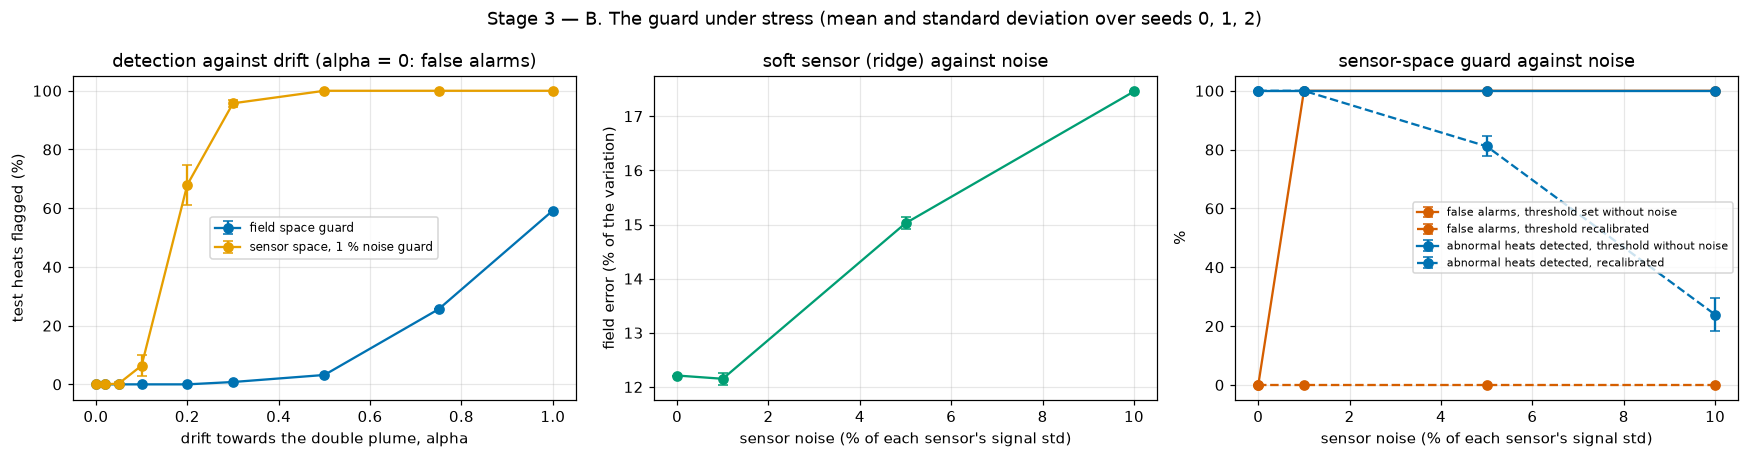

Result B: 90 % detection reached at alpha = None (field guard), 0.3 (sensor guard, 1 % noise); noise 0 / 1 / 5 / 10 %: soft sensor 0.122 / 0.122 / 0.150 / 0.175, false alarms with the clean threshold 0.00 / 1.00 / 1.00 / 1.00, recalibrated 0.00 / 0.00 / 0.00 / 0.00, abnormal detected (recalibrated) 1.00 / 1.00 / 0.81 / 0.24


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for gname, c in (("field space", CB[0]), ("sensor space, 1 % noise", CB[1])):
    d = B1[("mean", gname)]; e = B1[("std", gname)].fillna(0)
    ax[0].errorbar(B1.index, 100 * d, yerr=100 * e, fmt="o-", color=c, capsize=3, label=gname + " guard")
ax[0].set_xlabel("drift towards the double plume, alpha"); ax[0].set_ylabel("test heats flagged (%)"); ax[0].set_title("detection against drift (alpha = 0: false alarms)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
x = 100 * np.array(NOISE)
ax[1].errorbar(x, 100 * B2.soft_sensor_relL2_mean, yerr=100 * B2.soft_sensor_relL2_std, fmt="o-", color=CB[2], capsize=3)
ax[1].set_xlabel("sensor noise (% of each sensor's signal std)"); ax[1].set_ylabel("field error (% of the variation)"); ax[1].set_title("soft sensor (ridge) against noise"); ax[1].grid(alpha=0.3)
for col, lab, c, ls in (("false_alarm_clean_threshold", "false alarms, threshold set without noise", CB[3], "-"), ("false_alarm_recalibrated", "false alarms, threshold recalibrated", CB[3], "--"),
                        ("detection_clean_threshold", "abnormal heats detected, threshold without noise", CB[0], "-"), ("detection_recalibrated", "abnormal heats detected, recalibrated", CB[0], "--")):
    ax[2].errorbar(x, 100 * B2[f"{col}_mean"], yerr=100 * B2[f"{col}_std"], fmt="o" + ls, color=c, capsize=3, label=lab)
ax[2].set_xlabel("sensor noise (% of each sensor's signal std)"); ax[2].set_ylabel("%"); ax[2].set_title("sensor-space guard against noise"); ax[2].legend(fontsize=7); ax[2].grid(alpha=0.3)
fig.suptitle("Stage 3 — B. The guard under stress (mean and standard deviation over seeds 0, 1, 2)"); plt.tight_layout(); plt.savefig(RES / "b_guard.png", dpi=110); plt.show()
first = lambda gname: next((a for a in B1.index if B1.loc[a, ("mean", gname)] >= 0.9), None)
print(f"Result B: 90 % detection reached at alpha = {first('field space')} (field guard), {first('sensor space, 1 % noise')} (sensor guard, 1 % noise); "
      + "noise 0 / 1 / 5 / 10 %: soft sensor " + " / ".join(f"{v:.3f}" for v in B2.soft_sensor_relL2_mean) + ", false alarms with the clean threshold " + " / ".join(f"{v:.2f}" for v in B2.false_alarm_clean_threshold_mean)
      + ", recalibrated " + " / ".join(f"{v:.2f}" for v in B2.false_alarm_recalibrated_mean) + ", abnormal detected (recalibrated) " + " / ".join(f"{v:.2f}" for v in B2.detection_recalibrated_mean))